In [1]:
print("Mon projet F1 - Risque de crédit en Allemagne")
print("Environnement Python prêt !")

Mon projet F1 - Risque de crédit en Allemagne
Environnement Python prêt !


Étape 2 — Préparer l'environnement Python

In [2]:
# Installation des bibliothèques nécessaires

!pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
# Importation des bibliothèques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

# Affichage des versions

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)

print("\nToutes les bibliothèques sont importées avec succès !")

Pandas : 2.2.3
NumPy : 2.4.6
Scikit-learn : 1.6.1

Toutes les bibliothèques sont importées avec succès !


In [4]:
# Télécharger le véritable dataset depuis UCI

!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo

# Récupération du dataset officiel
german_credit = fetch_ucirepo(id=144)

# Séparer les variables explicatives et la cible
X = german_credit.data.features
y = german_credit.data.targets

# Construire le DataFrame final
df = X.copy()
df["Risk"] = y.iloc[:, 0]

print("Dataset téléchargé avec succès !")
print("Dimensions :", df.shape)

display(df.head())

Dataset téléchargé avec succès !
Dimensions : (1000, 21)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [5]:
print("Répartition des classes :")
print(df["Risk"].value_counts())

print("\nInformations du dataset :")
df.info()

Répartition des classes :
Risk
1    700
2    300
Name: count, dtype: int64

Informations du dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Attribute1   1000 non-null   object
 1   Attribute2   1000 non-null   int64 
 2   Attribute3   1000 non-null   object
 3   Attribute4   1000 non-null   object
 4   Attribute5   1000 non-null   int64 
 5   Attribute6   1000 non-null   object
 6   Attribute7   1000 non-null   object
 7   Attribute8   1000 non-null   int64 
 8   Attribute9   1000 non-null   object
 9   Attribute10  1000 non-null   object
 10  Attribute11  1000 non-null   int64 
 11  Attribute12  1000 non-null   object
 12  Attribute13  1000 non-null   int64 
 13  Attribute14  1000 non-null   object
 14  Attribute15  1000 non-null   object
 15  Attribute16  1000 non-null   int64 
 16  Attribute17  1000 non-null   object
 17  Attribut

Étape 3 — Description du jeu de données

In [6]:
# Dimensions du dataset
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

# Afficher les 5 premières observations
display(df.head())

# Afficher les 5 dernières observations
display(df.tail())

Nombre de lignes : 1000
Nombre de colonnes : 21


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Risk
995,A14,12,A32,A42,1736,A61,A74,3,A92,A101,...,A121,31,A143,A152,1,A172,1,A191,A201,1
996,A11,30,A32,A41,3857,A61,A73,4,A91,A101,...,A122,40,A143,A152,1,A174,1,A192,A201,1
997,A14,12,A32,A43,804,A61,A75,4,A93,A101,...,A123,38,A143,A152,1,A173,1,A191,A201,1
998,A11,45,A32,A43,1845,A61,A73,4,A93,A101,...,A124,23,A143,A153,1,A173,1,A192,A201,2
999,A12,45,A34,A41,4576,A62,A71,3,A93,A101,...,A123,27,A143,A152,1,A173,1,A191,A201,1


In [7]:
# Informations générales
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Attribute1   1000 non-null   object
 1   Attribute2   1000 non-null   int64 
 2   Attribute3   1000 non-null   object
 3   Attribute4   1000 non-null   object
 4   Attribute5   1000 non-null   int64 
 5   Attribute6   1000 non-null   object
 6   Attribute7   1000 non-null   object
 7   Attribute8   1000 non-null   int64 
 8   Attribute9   1000 non-null   object
 9   Attribute10  1000 non-null   object
 10  Attribute11  1000 non-null   int64 
 11  Attribute12  1000 non-null   object
 12  Attribute13  1000 non-null   int64 
 13  Attribute14  1000 non-null   object
 14  Attribute15  1000 non-null   object
 15  Attribute16  1000 non-null   int64 
 16  Attribute17  1000 non-null   object
 17  Attribute18  1000 non-null   int64 
 18  Attribute19  1000 non-null   object
 19  Attribute20  1000 non-null  

In [8]:
# Statistiques descriptives
display(df.describe(include="all"))

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Risk
count,1000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,1000,1000,...,1000,1000.000000,1000,1000,1000.000000,1000,1000.000000,1000,1000,1000.000000
unique,4,NaN,5,10,NaN,5,5,NaN,4,3,...,4,NaN,3,3,NaN,4,NaN,2,2,NaN
top,A14,NaN,A32,A43,NaN,A61,A73,NaN,A93,A101,...,A123,NaN,A143,A152,NaN,A173,NaN,A191,A201,NaN
freq,394,NaN,530,280,NaN,603,339,NaN,548,907,...,332,NaN,814,713,NaN,630,NaN,596,963,NaN
mean,NaN,20.903000,NaN,NaN,3271.258000,NaN,NaN,2.973000,NaN,NaN,...,NaN,35.546000,NaN,NaN,1.407000,NaN,1.155000,NaN,NaN,1.300000
std,NaN,12.058814,NaN,NaN,2822.736876,NaN,NaN,1.118715,NaN,NaN,...,NaN,11.375469,NaN,NaN,0.577654,NaN,0.362086,NaN,NaN,0.458487
min,NaN,4.000000,NaN,NaN,250.000000,NaN,NaN,1.000000,NaN,NaN,...,NaN,19.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
25%,NaN,12.000000,NaN,NaN,1365.500000,NaN,NaN,2.000000,NaN,NaN,...,NaN,27.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
50%,NaN,18.000000,NaN,NaN,2319.500000,NaN,NaN,3.000000,NaN,NaN,...,NaN,33.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
75%,NaN,24.000000,NaN,NaN,3972.250000,NaN,NaN,4.000000,NaN,NaN,...,NaN,42.000000,NaN,NaN,2.000000,NaN,1.000000,NaN,NaN,2.000000


In [9]:
# Répartition des risques
print(df["Risk"].value_counts())

# Pourcentages
print(df["Risk"].value_counts(normalize=True) * 100)

Risk
1    700
2    300
Name: count, dtype: int64
Risk
1    70.0
2    30.0
Name: proportion, dtype: float64


In [10]:
# Valeurs manquantes
print("Valeurs manquantes :")
print(df.isnull().sum())

# Nombre de doublons
print("\nNombre de doublons :", df.duplicated().sum())

Valeurs manquantes :
Attribute1     0
Attribute2     0
Attribute3     0
Attribute4     0
Attribute5     0
Attribute6     0
Attribute7     0
Attribute8     0
Attribute9     0
Attribute10    0
Attribute11    0
Attribute12    0
Attribute13    0
Attribute14    0
Attribute15    0
Attribute16    0
Attribute17    0
Attribute18    0
Attribute19    0
Attribute20    0
Risk           0
dtype: int64

Nombre de doublons : 0


In [11]:
# Export du dataset original récupéré depuis UCI

df.to_csv("german_credit.csv", index=False)

print("Dataset enregistré avec succès !")

Dataset enregistré avec succès !


Étape 4 — Exploration des données (EDA)

In [12]:
# Sélection des variables numériques
numeric_columns = df.select_dtypes(include=np.number).columns

# Statistiques descriptives
display(df[numeric_columns].describe())

,Attribute2,Attribute5,Attribute8,Attribute11,Attribute13,Attribute16,Attribute18,Risk
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000


Risk
1    700
2    300
Name: count, dtype: int64


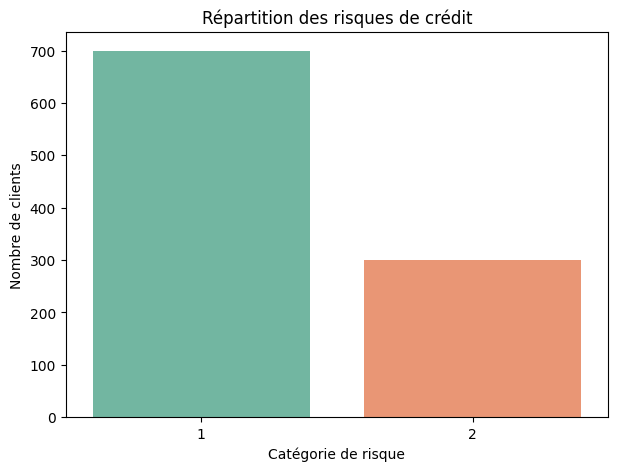

In [13]:
# Nombre de bons et mauvais risques
risk_counts = df["Risk"].value_counts()

print(risk_counts)

# Graphique
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Risk", hue="Risk", palette="Set2", legend=False)

plt.title("Répartition des risques de crédit")
plt.xlabel("Catégorie de risque")
plt.ylabel("Nombre de clients")
plt.show()

Les données présentent deux catégories de risque : les bons risques et les mauvais risques. La classe majoritaire représente les clients ayant un bon risque de crédit. Cette différence de fréquence montre un déséquilibre entre les classes, qu'il faudra prendre en considération lors de l'évaluation du modèle.

In [21]:
print("Dimensions :", df.shape)
print("Noms des colonnes :", df.columns.tolist())

Dimensions : (1000, 21)
Noms des colonnes : ['Attribute1', 'Attribute2', 'Attribute3', 'Attribute4', 'Attribute5', 'Attribute6', 'Attribute7', 'Attribute8', 'Attribute9', 'Attribute10', 'Attribute11', 'Attribute12', 'Attribute13', 'Attribute14', 'Attribute15', 'Attribute16', 'Attribute17', 'Attribute18', 'Attribute19', 'Attribute20', 'Risk']


In [18]:
print(df.columns.tolist())

['Attribute1', 'Attribute2', 'Attribute3', 'Attribute4', 'Attribute5', 'Attribute6', 'Attribute7', 'Attribute8', 'Attribute9', 'Attribute10', 'Attribute11', 'Attribute12', 'Attribute13', 'Attribute14', 'Attribute15', 'Attribute16', 'Attribute17', 'Attribute18', 'Attribute19', 'Attribute20', 'Risk']


In [22]:
# Renommer les variables du dataset German Credit

new_columns = [
    "checking_status",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_status",
    "employment",
    "installment_commitment",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "num_dependents",
    "telephone",
    "foreign_worker"
]

# Vérifier le nombre de colonnes
assert len(new_columns) == 20

# Renommer les colonnes
df.columns = new_columns + ["Risk"]

# Vérification
print(df.columns.tolist())
display(df.head())

['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'telephone', 'foreign_worker', 'Risk']


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


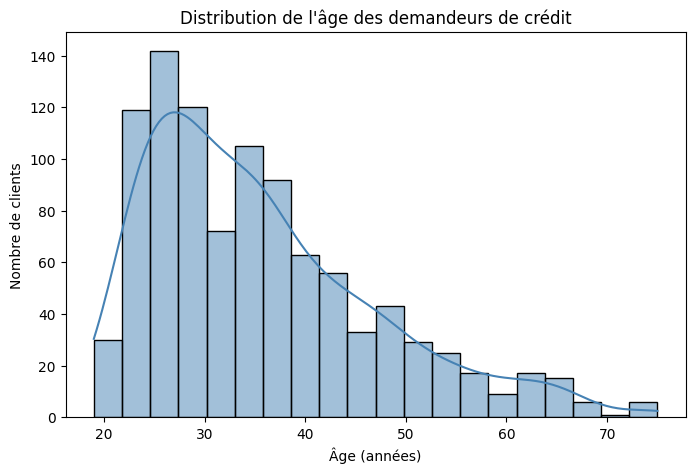

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution de l'âge des demandeurs de crédit")
plt.xlabel("Âge (années)")
plt.ylabel("Nombre de clients")

plt.show()

La distribution des âges permet d'identifier les tranches d'âge les plus représentées parmi les demandeurs de crédit. Cette variable peut être utile pour étudier les différences de profil entre les clients.

In [25]:
print("Répartition des risques :")
print(df["Risk"].value_counts())

print("\nTypes de données :")
print(df.dtypes)

Répartition des risques :
Risk
1    700
2    300
Name: count, dtype: int64

Types de données :
checking_status            object
duration                    int64
credit_history             object
purpose                    object
credit_amount               int64
savings_status             object
employment                 object
installment_commitment      int64
personal_status_sex        object
other_debtors              object
residence_since             int64
property                   object
age                         int64
other_installment_plans    object
housing                    object
existing_credits            int64
job                        object
num_dependents              int64
telephone                  object
foreign_worker             object
Risk                        int64
dtype: object


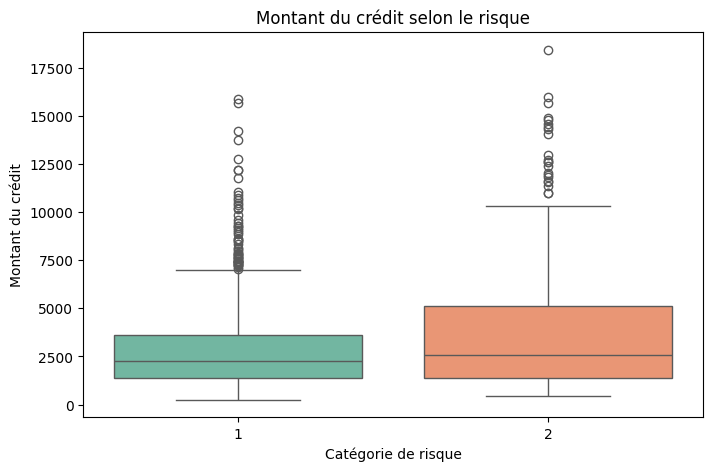

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Risk",
    y="credit_amount",
    hue="Risk",
    palette="Set2",
    legend=False
)

plt.title("Montant du crédit selon le risque")
plt.xlabel("Catégorie de risque")
plt.ylabel("Montant du crédit")

plt.show()

Ce graphique compare les montants des crédits entre les bons et les mauvais risques. Il permet d'observer les différences de médiane, de dispersion et la présence de valeurs extrêmes.

 Détecter les valeurs extrêmes

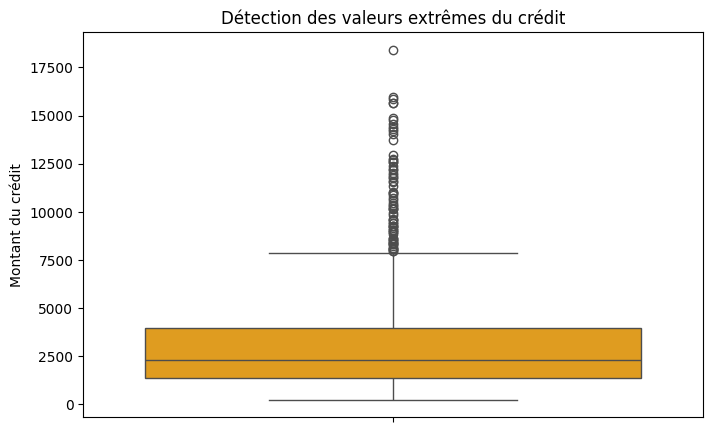

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    y="credit_amount",
    color="orange"
)

plt.title("Détection des valeurs extrêmes du crédit")
plt.ylabel("Montant du crédit")

plt.show()

5. Étudier les corrélations

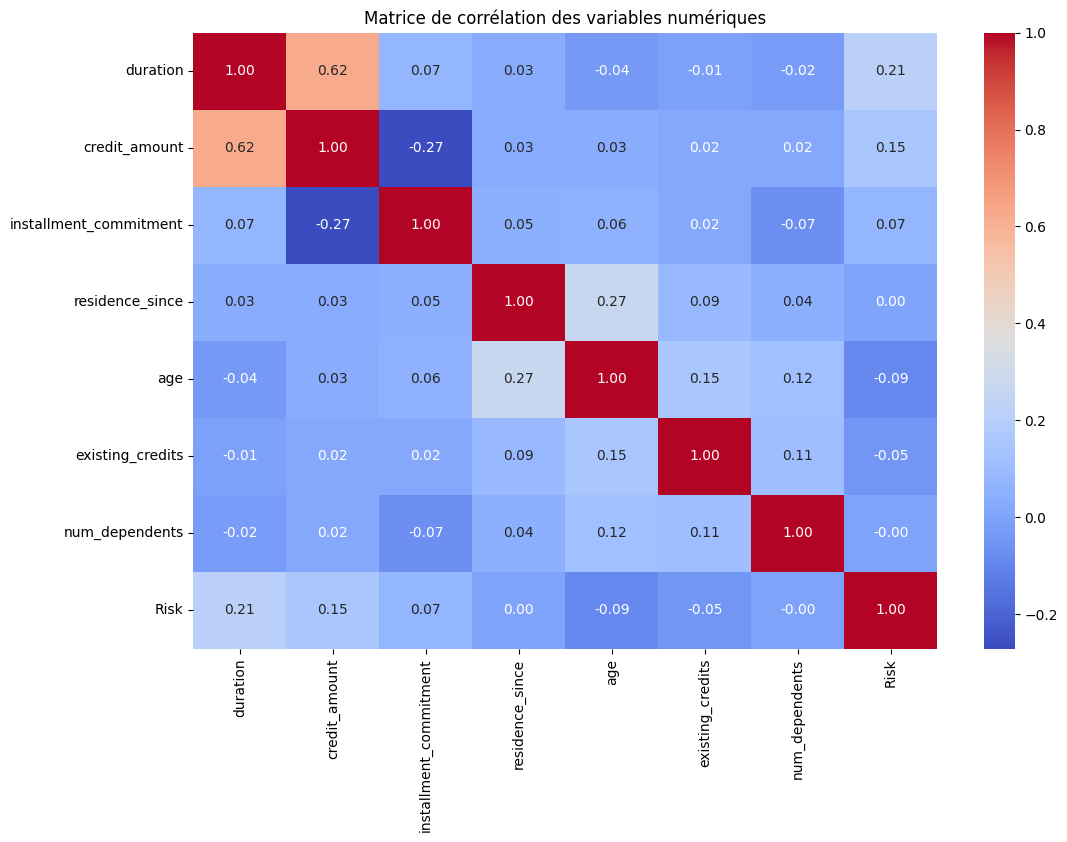

In [29]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation des variables numériques")

plt.show()

Étape 5 — Préparation des données

In [31]:
# Variables explicatives
X = df.drop("Risk", axis=1)

# Variable cible
y = df["Risk"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (1000, 20)
Dimensions de y : (1000,)


In [32]:
# Identifier les variables numériques
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# Identifier les variables catégorielles
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables numériques :", numeric_features)
print("\nVariables catégorielles :", categorical_features)

Variables numériques : ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Variables catégorielles : ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Taille apprentissage :", X_train.shape)
print("Taille test :", X_test.shape)

Taille apprentissage : (800, 20)
Taille test : (200, 20)


In [34]:
# Variables catégorielles
categorical_features = [
    "checking_status",
    "credit_history",
    "purpose",
    "savings_status",
    "employment",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

# Variables numériques
numeric_features = [
    "duration",
    "credit_amount",
    "installment_commitment",
    "residence_since",
    "age",
    "existing_credits",
    "num_dependents"
]

print("Nombre de variables catégorielles :", len(categorical_features))
print("Nombre de variables numériques :", len(numeric_features))

Nombre de variables catégorielles : 13
Nombre de variables numériques : 7


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Préparation des variables
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

print("Préprocesseur créé avec succès !")

Préprocesseur créé avec succès !


In [36]:
print("Valeurs de la cible :")
print(y.value_counts())

print("\nClasses disponibles :")
print(y.unique())

Valeurs de la cible :
Risk
1    700
2    300
Name: count, dtype: int64

Classes disponibles :
[1 2]


In [37]:
print(X_train.shape)
print(X_test.shape)
print(y.value_counts())

(800, 20)
(200, 20)
Risk
1    700
2    300
Name: count, dtype: int64


In [38]:
print(categorical_features)
print(numeric_features)

['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']


In [39]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Préparation des variables
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

# Création du modèle Random Forest
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

print("Pipeline Random Forest créé avec succès !")

Pipeline Random Forest créé avec succès !


In [40]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

print("Référence entraînée avec succès !")

Référence entraînée avec succès !


Étape 6 — Apprentissage et évaluation

In [41]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

# Prédictions de la référence
y_pred_baseline = baseline.predict(X_test)

# Évaluation
print("Résultats du modèle de référence")
print("--------------------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_baseline))
print("Precision :", precision_score(y_test, y_pred_baseline, pos_label=2))
print("Recall :", recall_score(y_test, y_pred_baseline, pos_label=2))
print("F1-score :", f1_score(y_test, y_pred_baseline, pos_label=2))

Résultats du modèle de référence
--------------------------------
Accuracy : 0.7
Precision : 0.0
Recall : 0.0
F1-score : 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=123,
    stratify=y
)

print("Apprentissage :", X_train.shape)
print("Test indépendant :", X_test.shape)

Apprentissage : (800, 20)
Test indépendant : (200, 20)


In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, recall_score

# Détection prioritaire des mauvais risques (classe 2)
scoring_recall = make_scorer(
    recall_score,
    pos_label=2
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores_baseline = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_recall
)

print("Scores de validation :", scores_baseline)
print("Recall moyen :", scores_baseline.mean())
print("Écart-type :", scores_baseline.std())

Scores de validation : [0. 0. 0. 0. 0.]
Recall moyen : 0.0
Écart-type : 0.0


Notre objectif principal sera de détecter les mauvais risques, sans oublier le coût des erreurs.

Optimisation de Random Forest

1. Importer GridSearchCV

In [44]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV importé avec succès !")

GridSearchCV importé avec succès !


2. Définir les hyperparamètres à tester

In [45]:
param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 5, 10, 15],
    "classifier__min_samples_leaf": [1, 3]
}

print("Nombre de configurations :",
      3 * 4 * 2)

Nombre de configurations : 24


3. Lancer l'optimisation

In [46]:
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring=scoring_recall,
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :")
print(grid_search.best_params_)

print("\nMeilleur Recall moyen :")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Meilleurs paramètres :
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 200}

Meilleur Recall moyen :
0.675


Récupérer le meilleur modèle

In [47]:
best_model = grid_search.best_estimator_

print("Meilleur modèle Random Forest obtenu !")

Meilleur modèle Random Forest obtenu !


5. Visualiser les résultats de validation

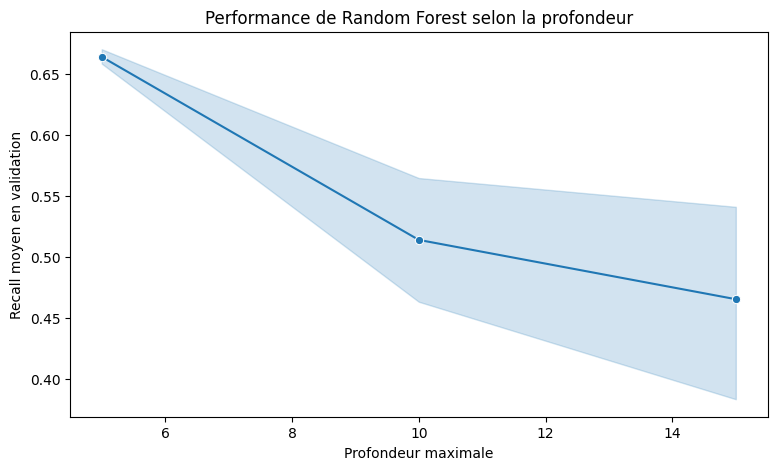

In [48]:
results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=results,
    x="param_classifier__max_depth",
    y="mean_test_score",
    marker="o"
)

plt.title("Performance de Random Forest selon la profondeur")
plt.xlabel("Profondeur maximale")
plt.ylabel("Recall moyen en validation")

plt.show()

In [49]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 200}
0.675


In [50]:
# Prédictions sur le jeu de test indépendant

y_pred = best_model.predict(X_test)

print("Prédictions réalisées avec succès !")

Prédictions réalisées avec succès !


In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy :", accuracy_score(y_test, y_pred))

print("Precision :", precision_score(
    y_test, y_pred, pos_label=2
))

print("Recall :", recall_score(
    y_test, y_pred, pos_label=2
))

print("F1-score :", f1_score(
    y_test, y_pred, pos_label=2
))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

Accuracy : 0.69
Precision : 0.4878048780487805
Recall : 0.6666666666666666
F1-score : 0.5633802816901409

Rapport de classification :
              precision    recall  f1-score   support

           1       0.83      0.70      0.76       140
           2       0.49      0.67      0.56        60

    accuracy                           0.69       200
   macro avg       0.66      0.68      0.66       200
weighted avg       0.73      0.69      0.70       200



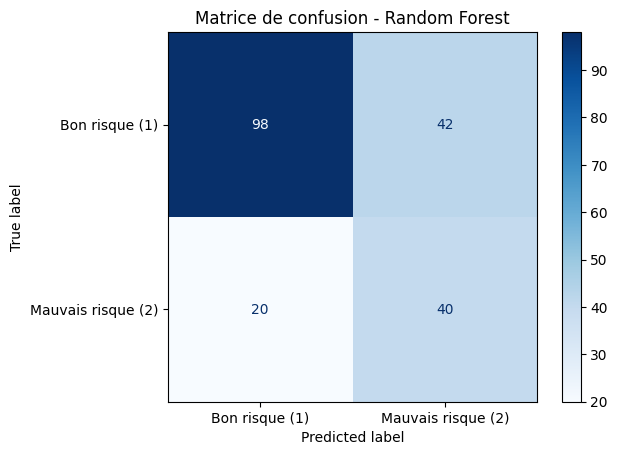

In [52]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[1, 2])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Bon risque (1)", "Mauvais risque (2)"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matrice de confusion - Random Forest")
plt.show()

In [53]:
# Référence sur le même jeu de test
y_pred_dummy = baseline.predict(X_test)

# Comparaison
comparison = pd.DataFrame({
    "Modele": ["DummyClassifier", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_dummy),
        accuracy_score(y_test, y_pred)
    ],
    "Recall_mauvais_risque": [
        recall_score(y_test, y_pred_dummy, pos_label=2),
        recall_score(y_test, y_pred, pos_label=2)
    ],
    "F1_mauvais_risque": [
        f1_score(y_test, y_pred_dummy, pos_label=2),
        f1_score(y_test, y_pred, pos_label=2)
    ]
})

display(comparison)

,Modele,Accuracy,Recall_mauvais_risque,F1_mauvais_risque
0,DummyClassifier,0.70,0.000000,0.00000
1,Random Forest,0.69,0.666667,0.56338


Étape 7 — Analyse des erreurs et seuil de décision

In [54]:
# Création d'un tableau comparatif des prédictions

resultats = X_test.copy()

resultats["Risque_reel"] = y_test
resultats["Risque_predit"] = y_pred

resultats["Erreur"] = (
    resultats["Risque_reel"] != resultats["Risque_predit"]
)

print("Nombre total d'erreurs :",
      resultats["Erreur"].sum())

print("\nObservations mal classées :")

display(resultats[resultats["Erreur"]].head(10))

Nombre total d'erreurs : 62

Observations mal classées :


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status_sex,other_debtors,...,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,Risque_reel,Risque_predit,Erreur
285,A11,47,A32,A40,10722,A61,A72,1,A92,A101,...,A143,A152,1,A172,1,A192,A201,1,2,True
543,A13,18,A32,A42,2864,A61,A73,2,A93,A101,...,A143,A152,1,A172,2,A191,A201,2,1,True
770,A11,24,A32,A41,2812,A65,A75,2,A92,A101,...,A143,A151,1,A173,1,A191,A201,1,2,True
651,A12,12,A32,A42,1922,A61,A73,4,A93,A101,...,A143,A152,1,A172,1,A191,A201,2,1,True
51,A12,27,A33,A41,5965,A61,A75,1,A93,A101,...,A143,A152,2,A174,1,A192,A201,1,2,True
438,A11,42,A34,A45,3394,A61,A71,4,A93,A102,...,A143,A152,2,A171,1,A191,A201,1,2,True
777,A11,18,A32,A43,3509,A61,A74,4,A92,A103,...,A143,A152,1,A173,1,A191,A201,1,2,True
148,A11,36,A34,A42,5371,A61,A73,3,A93,A103,...,A143,A152,2,A173,1,A191,A201,1,2,True
966,A12,27,A34,A43,2520,A63,A73,4,A93,A101,...,A143,A152,2,A172,1,A191,A201,2,1,True
68,A14,36,A32,A46,1819,A61,A73,4,A93,A101,...,A142,A153,1,A173,1,A192,A201,2,1,True


Ce tableau permet d'identifier les dossiers de crédit mal classés par le modèle. Ces erreurs sont importantes car elles peuvent entraîner des décisions financières inappropriées.

In [55]:
# Récupérer les variables après encodage

feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = best_model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Variable": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(10))

,Variable,Importance
3,cat__checking_status_A14,0.166611
0,cat__checking_status_A11,0.089883
55,num__credit_amount,0.079454
54,num__duration,0.078260
8,cat__credit_history_A34,0.059498
58,num__age,0.039734
19,cat__savings_status_A61,0.032151
1,cat__checking_status_A12,0.023698
36,cat__property_A121,0.019451
39,cat__property_A124,0.018061


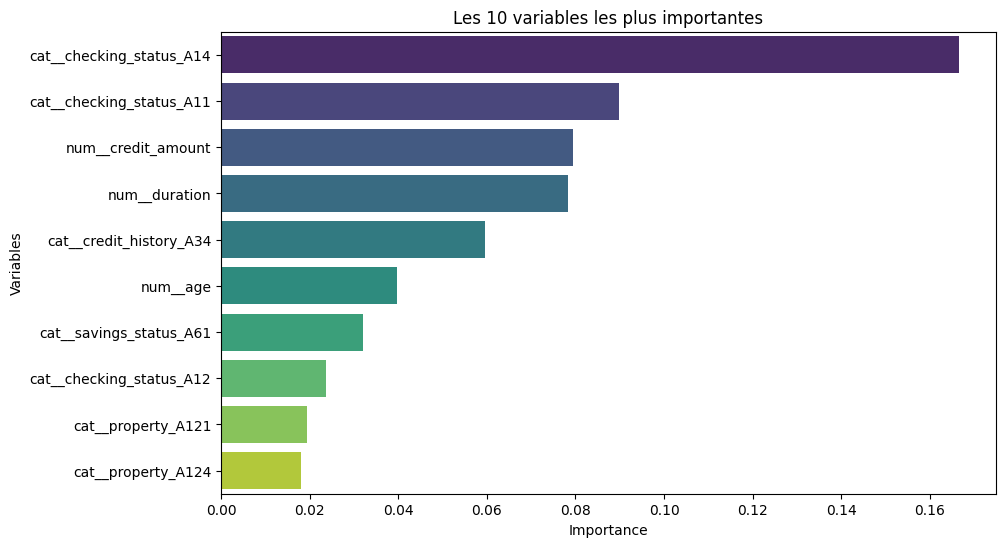

In [56]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Variable",
    hue="Variable",
    palette="viridis",
    legend=False
)

plt.title("Les 10 variables les plus importantes")
plt.xlabel("Importance")
plt.ylabel("Variables")

plt.show()

Ce graphique présente les variables les plus utilisées par Random Forest pour effectuer ses prédictions. Une importance élevée indique une contribution importante aux décisions du modèle, mais ne prouve pas une relation de causalité.

 Choisir le seuil de décision
Par défaut, Random Forest utilise généralement un seuil de 0,5 pour classifier les observations.

Mais dans notre projet, les erreurs n'ont pas toutes le même coût.

Nous allons tester plusieurs seuils sans toucher au jeu de test.

Pour cela, nous allons créer un jeu de validation à partir de l'apprentissage.

In [57]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

# Réentraîner le meilleur modèle sur le sous-ensemble d'apprentissage
threshold_model = grid_search.best_estimator_

threshold_model.fit(X_fit, y_fit)

# Probabilité d'appartenir à la classe 2 (mauvais risque)
classes = list(threshold_model.classes_)
bad_index = classes.index(2)

proba_bad = threshold_model.predict_proba(X_val)[:, bad_index]

print("Validation prête pour le choix du seuil.")

Validation prête pour le choix du seuil.


Pour illustrer la matrice de coûts couramment utilisée avec German Credit, nous allons retenir provisoirement :

Coût de 5 pour accepter un mauvais risque.

Coût de 1 pour refuser un bon risque.

Vérifie toutefois que ces coûts correspondent bien à ta fiche F1.

In [58]:
thresholds = np.arange(0.10, 0.91, 0.05)

cost_results = []

for threshold in thresholds:

    predictions = np.where(
        proba_bad >= threshold,
        2,
        1
    )

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[1, 2]
    )

    # Matrice :
    # [[bons acceptés, bons refusés],
    #  [mauvais acceptés, mauvais refusés]]

    cost = 1 * cm[0, 1] + 5 * cm[1, 0]

    cost_results.append({
        "Seuil": threshold,
        "Cout_total": cost
    })

cost_df = pd.DataFrame(cost_results)

display(cost_df)

best_threshold = cost_df.loc[
    cost_df["Cout_total"].idxmin(),
    "Seuil"
]

print("Meilleur seuil :", best_threshold)

,Seuil,Cout_total
0,0.10,140
1,0.15,139
2,0.20,135
3,0.25,127
4,0.30,118
5,0.35,117
6,0.40,100
7,0.45,106
8,0.50,139
9,0.55,167


Meilleur seuil : 0.40000000000000013


Comparer les coûts selon le seuil

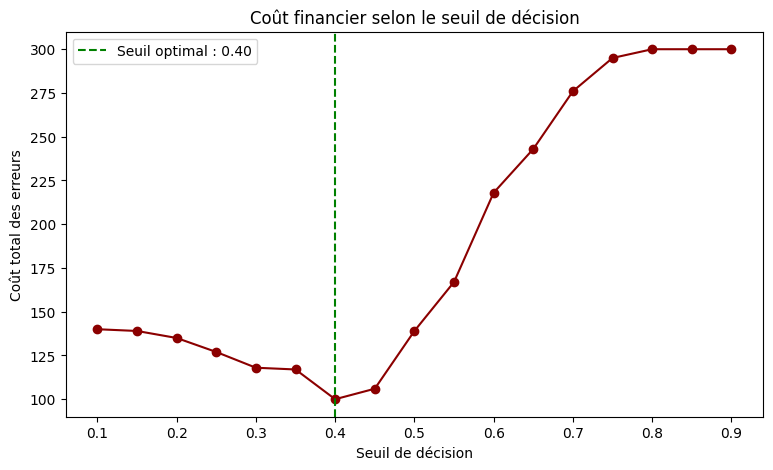

In [59]:
plt.figure(figsize=(9, 5))

plt.plot(
    cost_df["Seuil"],
    cost_df["Cout_total"],
    marker="o",
    color="darkred"
)

plt.axvline(
    best_threshold,
    color="green",
    linestyle="--",
    label=f"Seuil optimal : {best_threshold:.2f}"
)

plt.title("Coût financier selon le seuil de décision")
plt.xlabel("Seuil de décision")
plt.ylabel("Coût total des erreurs")
plt.legend()
plt.show()

Étape 8 — Analyse critique

8. Analyse critique

Le modèle Random Forest permet d'identifier les profils présentant un risque de crédit élevé à partir de plusieurs caractéristiques des demandeurs.

Cependant, plusieurs limites doivent être prises en considération. Premièrement, le dataset German Credit contient seulement 1 000 observations, ce qui limite la capacité de généralisation du modèle à d'autres populations. Deuxièmement, les classes sont déséquilibrées, avec 70 % de bons risques et 30 % de mauvais risques.

Par ailleurs, le modèle Random Forest est composé de plusieurs arbres de décision, ce qui rend son interprétation moins directe qu'un modèle linéaire. Les importances des variables indiquent leur contribution aux prédictions, mais ne permettent pas d'établir des relations de causalité.

Enfin, les coûts des erreurs de classification doivent être pris en compte dans la décision finale. Une mauvaise classification d'un client présentant un risque élevé peut entraîner une perte financière importante.

Pour améliorer ce travail, il serait intéressant d'utiliser un dataset plus récent et plus volumineux, de comparer plusieurs algorithmes et d'étudier davantage les méthodes d'explicabilité.

Étape 9 — Conclusion du projet

9. Conclusion

Ce projet avait pour objectif de développer un modèle de Machine Learning permettant de prédire le risque de crédit des demandeurs à partir du dataset German Credit.

La démarche a consisté à explorer les données, préparer les variables, entraîner un modèle Random Forest et optimiser ses hyperparamètres avec GridSearchCV.

Le modèle obtenu présente un rappel moyen de 67,5 % en validation croisée pour la détection des mauvais risques. Ce résultat montre que le modèle identifie une partie importante des profils risqués, mais que des améliorations restent nécessaires.

En conclusion, le Machine Learning peut constituer un outil d'aide à la décision pour l'évaluation du risque de crédit, à condition de tenir compte des coûts des erreurs, des limites des données et de la capacité de généralisation du modèle.

Étape 10 — Références et reproductibilité

10. Références et reproductibilité

Source des données :

UCI Machine Learning Repository – Statlog German Credit Data.
https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

Bibliothèques utilisées :

Python
Pandas
NumPy
Matplotlib
Seaborn
Scikit-learn

Algorithme principal :

Random Forest Classifier.

Méthodes d'évaluation :

Accuracy
Precision
Recall
F1-score
Matrice de confusion
Validation croisée stratifiée.

Reproductibilité :

Graine aléatoire : 42.
Environnement : Google Colab.
Jeu de données : Statlog German Credit Data.
Dépôt GitHub : https://github.com/isselmou631/23008771-SIDI-ISSELMOU